### Import libraries

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)
import joblib

### Configure paths

In [3]:
# Project paths
PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "notebook" else Path.cwd()

DATA_PATH = PROJECT_DIR / "data" / "customer_churn_model_v2.csv"
OUTPUT_DIR = PROJECT_DIR / "notebook" / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Output directory:", OUTPUT_DIR.resolve())
print("Libraries imported successfully!")

Project directory: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Predictive Churn Analysis
Dataset path: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Predictive Churn Analysis\data\customer_churn_model_v2.csv
Output directory: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Predictive Churn Analysis\notebook\output
Libraries imported successfully!


### Load the CSV dataset

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place customer_churn_model_v2.csv inside the data folder."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 800
Number of columns: 13


,CustomerID,Age,Region,TenureMonths,SubscriptionType,MonthlyChargesINR,TotalChargesINR,ContractType,SupportTickets,LatePayments,PaymentMethod,AutoPay,Churn
0,CUST-100001,57,South,33,Standard,767.25,23893.97,Month-to-Month,4,1,UPI,Yes,Yes
1,CUST-100002,44,South,45,Basic,476.72,21627.46,Two Year,0,1,UPI,Yes,Yes
2,CUST-100003,64,South,57,Basic,414.81,22500.07,One Year,1,1,UPI,No,Yes
3,CUST-100004,57,East,44,Pro,1171.76,50309.16,Month-to-Month,4,0,Card,Yes,Yes
4,CUST-100005,58,North,49,Pro,1130.19,55980.21,Month-to-Month,3,0,Wallet,No,No


### Inspect the dataset

In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         800 non-null    str    
 1   Age                800 non-null    int64  
 2   Region             800 non-null    str    
 3   TenureMonths       800 non-null    int64  
 4   SubscriptionType   800 non-null    str    
 5   MonthlyChargesINR  800 non-null    float64
 6   TotalChargesINR    800 non-null    float64
 7   ContractType       800 non-null    str    
 8   SupportTickets     800 non-null    int64  
 9   LatePayments       800 non-null    int64  
 10  PaymentMethod      800 non-null    str    
 11  AutoPay            800 non-null    str    
 12

,Missing Values
CustomerID,0
Age,0
Region,0
TenureMonths,0
SubscriptionType,0
MonthlyChargesINR,0
TotalChargesINR,0
ContractType,0
SupportTickets,0
LatePayments,0



Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,800,800,CUST-100001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,800.0,NaN,NaN,NaN,44.0,14.448822,18.0,32.0,44.0,56.0,68.0
Region,800,5,South,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TenureMonths,800.0,NaN,NaN,NaN,37.23,20.467003,0.0,19.75,37.0,56.0,72.0
SubscriptionType,800,3,Basic,278,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthlyChargesINR,800.0,NaN,NaN,NaN,747.905125,288.4257,364.47,451.445,717.46,1093.01,1183.96
TotalChargesINR,800.0,NaN,NaN,NaN,27440.590013,19421.452781,0.0,12521.705,23661.635,38513.11,83229.0
ContractType,800,3,Month-to-Month,432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SupportTickets,800.0,NaN,NaN,NaN,1.83625,1.437713,0.0,1.0,2.0,3.0,6.0
LatePayments,800.0,NaN,NaN,NaN,1.32,1.136536,0.0,0.0,1.0,2.0,5.0


### Clean the data and explore churn distribution

In [6]:

# Make a working copy
df_clean = df.copy()

# Remove duplicate rows, if any
df_clean = df_clean.drop_duplicates()

# Remove records with missing target values, if any
df_clean = df_clean.dropna(subset=["Churn"])

# Remove the customer ID because it is only an identifier
df_clean = df_clean.drop(columns=["CustomerID"])

# Standardize target labels
df_clean["Churn"] = (
    df_clean["Churn"]
    .astype(str)
    .str.strip()
    .str.title()
)

# Validate the target labels
print("Target classes:", df_clean["Churn"].unique())

assert set(df_clean["Churn"].unique()) == {"Yes", "No"}, (
    "Unexpected churn labels found. Inspect the target values."
)

print("\nCleaned dataset shape:", df_clean.shape)
print("\nChurn counts:")
print(df_clean["Churn"].value_counts())

print("\nChurn percentages:")
print(
    (df_clean["Churn"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)


Target classes: <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Cleaned dataset shape: (800, 12)

Churn counts:
Churn
No     466
Yes    334
Name: count, dtype: int64

Churn percentages:
Churn
No     58.25%
Yes    41.75%
Name: proportion, dtype: str


### Visualize the churn distribution

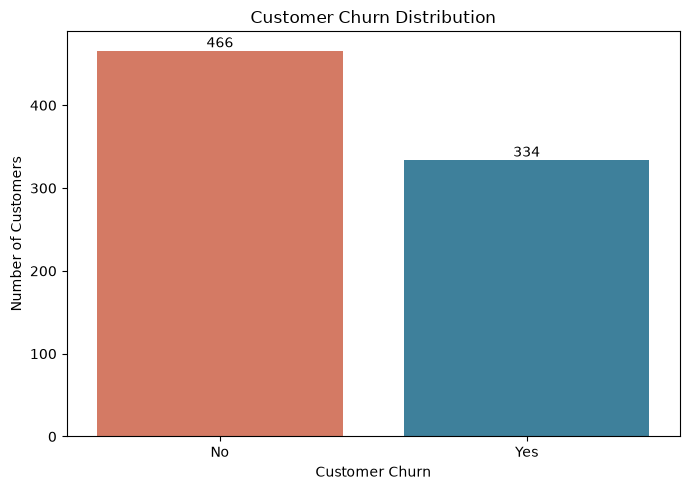

In [7]:

# Step 2.1: Visualize target distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df_clean,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette=["#2E86AB", "#E76F51"],
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


### Separate features and target
The model should learn from customer attributes and predict Churn.

In [8]:


X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget encoding:")
print("No churn = 0")
print("Churn = 1")

print("\nFeature columns:")
print(X.columns.tolist())

print("\nEncoded target distribution:")
print(y.value_counts())


Feature matrix shape: (800, 11)
Target shape: (800,)

Target encoding:
No churn = 0
Churn = 1

Feature columns:
['Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay']

Encoded target distribution:
Churn
0    466
1    334
Name: count, dtype: int64


### Split the dataset (80/20)

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training features: (640, 11)
Testing features: (160, 11)

Training target distribution:
Churn
0    373
1    267
Name: count, dtype: int64

Testing target distribution:
Churn
0    93
1    67
Name: count, dtype: int64

Training churn rate: 41.72 %
Testing churn rate: 41.88 %


Expected sizes:
- Training set: 640 customers
- Testing set: 160 customers
- Training and testing sets should have similar churn percentages.
### Build the preprocessing pipeline
We'll use:
- MinMaxScaler for numeric features.
- OneHotEncoder for categorical features.
- SimpleImputer to handle missing values if they appear in future data.
This preprocessing will be fitted only on the training set through the model pipeline, preventing information leakage from the test set.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Numeric preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("\nPreprocessing pipeline created successfully!")

Numeric features: ['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments']
Categorical features: ['Region', 'SubscriptionType', 'ContractType', 'PaymentMethod', 'AutoPay']

Preprocessing pipeline created successfully!


### Train the machine learning models
What this code does:
- Applies your preprocessing pipeline to the features.
- Uses Logistic Regression as a baseline model.
- Uses Random Forest to learn more complex patterns.
- Uses class_weight="balanced" to account for the difference between churn and non-churn customers.
- Stores both trained models for evaluation and prediction.

In [11]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Define the machine learning models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Train each model and store the fitted pipelines
fitted_models = {}

for name, classifier in models.items():
    print(f"Training {name}...")

    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model_pipeline.fit(X_train, y_train)
    fitted_models[name] = model_pipeline

    print(f"{name} trained successfully!\n")

print("All models trained successfully!")


Training Logistic Regression...
Logistic Regression trained successfully!

Training Random Forest...
Random Forest trained successfully!

All models trained successfully!


### Evaluate and compare the models

In [12]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in fitted_models.items():
    # Predict churn labels and probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Display comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(
    results_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.669,0.583,0.731,0.649,0.681
1,Random Forest,0.637,0.557,0.657,0.603,0.658


### Understanding the metrics
Metric	What it tells you
- Accuracy	: Overall percentage of correct predictions
- Precision	: How many customers predicted to churn actually churned
- Recall	: How many actual churners the model successfully identified
- F1 Score	: Balance between precision and recall
- ROC-AUC	: How well the model distinguishes churners from non-churners

For a churn prediction task, recall and F1 score are particularly important, because missing a customer who is likely to leave can be costly. ROC-AUC also helps compare the models' ability to distinguish the two classes.

### Generate confusion matrices and classification reports


Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.76      0.62      0.69        93
       Churn       0.58      0.73      0.65        67

    accuracy                           0.67       160
   macro avg       0.67      0.68      0.67       160
weighted avg       0.69      0.67      0.67       160



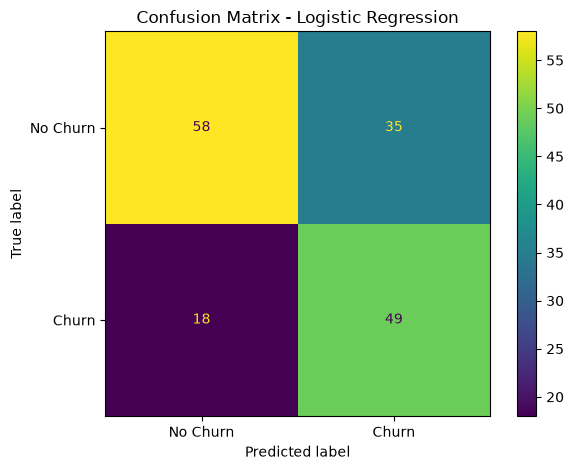


Random Forest

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.72      0.62      0.67        93
       Churn       0.56      0.66      0.60        67

    accuracy                           0.64       160
   macro avg       0.64      0.64      0.63       160
weighted avg       0.65      0.64      0.64       160



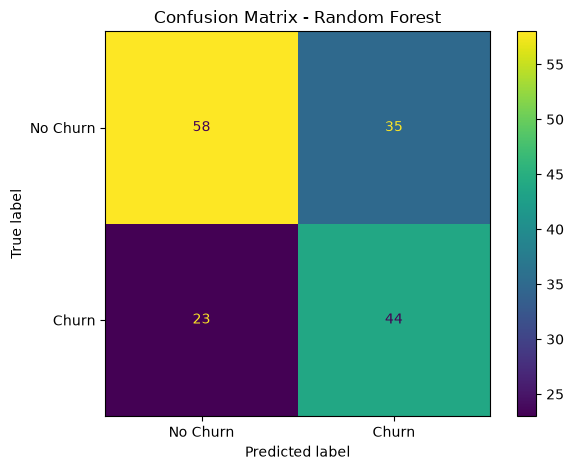

In [13]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

for name, model in fitted_models.items():
    y_pred = model.predict(X_test)

    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    display_plot.plot(values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


### Plot the ROC curves

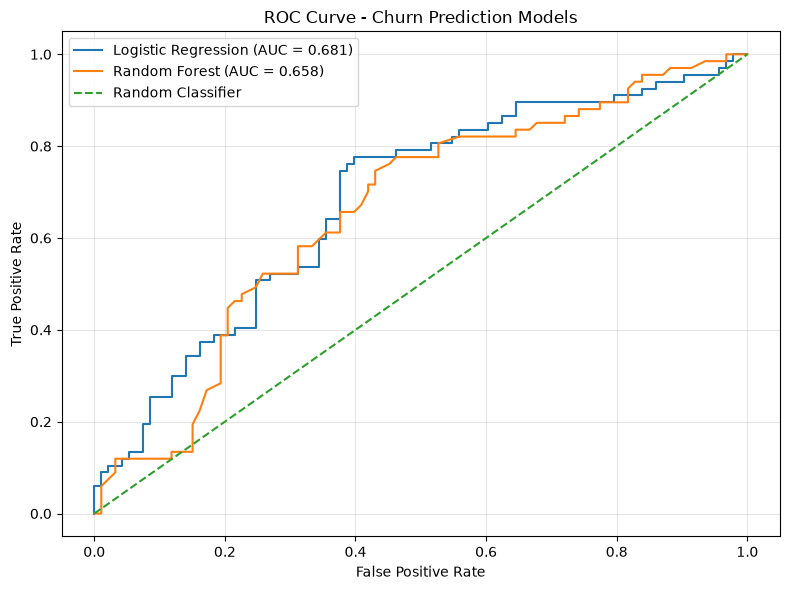

In [14]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, model in fitted_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random-classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Churn Prediction Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Export churn-risk predictions

In [15]:

from pathlib import Path
import pandas as pd

# Create the output directory
OUTPUT_DIR = Path.cwd()

if OUTPUT_DIR.name.lower() != "output":
    if OUTPUT_DIR.name.lower() == "notebook":
        OUTPUT_DIR = OUTPUT_DIR / "output"
    else:
        OUTPUT_DIR = OUTPUT_DIR / "notebook" / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the current best model
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

# Generate predictions
predicted_labels = best_model.predict(X_test)
churn_probabilities = best_model.predict_proba(X_test)[:, 1]

# Build the export table
predictions_df = pd.DataFrame({
    "ActualChurn": y_test.map({0: "No", 1: "Yes"}).to_numpy(),
    "PredictedChurn": pd.Series(predicted_labels, index=y_test.index)
        .map({0: "No", 1: "Yes"}).to_numpy(),
    "ChurnProbability": churn_probabilities,
    "RiskCategory": [
        "High" if p >= 0.70 else
        "Medium" if p >= 0.40 else
        "Low"
        for p in churn_probabilities
    ]
}, index=y_test.index)

# Include customer IDs for practical identification
predictions_df.insert(
    0,
    "CustomerID",
    df.loc[X_test.index, "CustomerID"].to_numpy()
)

predictions_df = predictions_df.sort_values(
    "ChurnProbability", ascending=False
)

predictions_path = OUTPUT_DIR / "churn_risk_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

print("Best model:", best_model_name)
print("Predictions saved to:", predictions_path)
print("\nRisk category counts:")
print(predictions_df["RiskCategory"].value_counts())
display(predictions_df.head(10))


Best model: Logistic Regression
Predictions saved to: c:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Predictive Churn Analysis\notebook\output\churn_risk_predictions.csv

Risk category counts:
RiskCategory
Medium    68
Low       62
High      30
Name: count, dtype: int64


,CustomerID,ActualChurn,PredictedChurn,ChurnProbability,RiskCategory
523,CUST-100524,Yes,Yes,0.875657,High
423,CUST-100424,Yes,Yes,0.867309,High
216,CUST-100217,Yes,Yes,0.798852,High
418,CUST-100419,Yes,Yes,0.798122,High
438,CUST-100439,No,Yes,0.793588,High
534,CUST-100535,Yes,Yes,0.791324,High
608,CUST-100609,Yes,Yes,0.779248,High
118,CUST-100119,No,Yes,0.772217,High
224,CUST-100225,Yes,Yes,0.769637,High
171,CUST-100172,No,Yes,0.766398,High


### Save the model evaluation results

In [16]:

import json
import joblib
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Ensure the output directory exists
OUTPUT_DIR = Path(
    r"C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Predictive Churn Analysis\notebook\output"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Recalculate metrics and prepare a clean report
metrics = []

for name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    metrics.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

metrics_df = pd.DataFrame(metrics).sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

# Export CSV and JSON reports
metrics_df.to_csv(OUTPUT_DIR / "model_evaluation_metrics.csv", index=False)

with open(OUTPUT_DIR / "model_evaluation_report.json", "w", encoding="utf-8") as file:
    json.dump(metrics_df.to_dict(orient="records"), file, indent=4)

print("Evaluation metrics saved successfully!")
display(metrics_df.round(3))


Evaluation metrics saved successfully!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.669,0.583,0.731,0.649,0.681
1,Random Forest,0.638,0.557,0.657,0.603,0.658


### Save the trained best model

In [17]:

import joblib

best_model_name = metrics_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

model_path = OUTPUT_DIR / "best_churn_model.joblib"
joblib.dump(best_model, model_path)

print("Best model:", best_model_name)
print("Model saved to:", model_path)
print("Model size:", round(model_path.stat().st_size / 1024, 2), "KB")


Best model: Logistic Regression
Model saved to: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Predictive Churn Analysis\notebook\output\best_churn_model.joblib
Model size: 5.71 KB


### Save a text summary for your report

In [18]:

summary_path = OUTPUT_DIR / "project_summary.txt"

with open(summary_path, "w", encoding="utf-8") as file:
    file.write("PREDICTIVE CHURN ANALYSIS\n")
    file.write("=" * 45 + "\n\n")
    file.write("Dataset: customer_churn_model_v2.csv\n")
    file.write(f"Total records: {len(df_clean)}\n")
    file.write(f"Training records: {len(X_train)}\n")
    file.write(f"Testing records: {len(X_test)}\n")
    file.write(f"Overall churn rate: {(y.mean() * 100):.2f}%\n\n")
    file.write(f"Best model by ROC-AUC: {best_model_name}\n\n")
    file.write(metrics_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    file.write("\n\nNote: Metrics are calculated on the held-out test set.\n")

print("Project summary saved to:", summary_path)


Project summary saved to: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Predictive Churn Analysis\notebook\output\project_summary.txt
